In [1]:
import os
import pandas as pd
import numpy as np
from geopy.geocoders import Nominatim
from geopy.distance import geodesic
import time
import re
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("weatherAUS.csv")



In [2]:
#přidání okolních měst pro větší přesnost předpovědi
target_city = "Melbourne"
mesta = data['Location'].unique()
geolocator = Nominatim(user_agent="weather_project")
cords = {}
for mesto in mesta:
    cisty_nazev = re.sub(r'([a-z])([A-Z])', r'\1 \2', mesto)
    dotaz = f"{cisty_nazev}, Australia"
    lokace = geolocator.geocode(dotaz)
    if lokace:
        cords[mesto] = (lokace.latitude, lokace.longitude)
    else:
        # Kdyby náhodou letiště stále nenašel, zkusíme explicitní dotaz
        lokace_alt = geolocator.geocode(f"{cisty_nazev} Victoria, Australia")
        if lokace_alt:
            cords[mesto] = (lokace_alt.latitude, lokace_alt.longitude)
    time.sleep(1)
target_cords = cords[target_city]
vzdalenosti = {}
for mesto, bod in cords.items():
    vzdalenosti[mesto]= round(geodesic(target_cords, bod).kilometers,1)
nejblizsi = sorted(vzdalenosti.items(), key= lambda x: x[1])

In [3]:
#Úprava dat
nejblizsi3 = [ mesto for mesto, dist in nejblizsi[:4]]
vzdalenostti3 = dict(nejblizsi[:4])
filtereddata = data [data['Location'].isin(nejblizsi3) & (data['Location'] != 'Richmond') ].copy() #richmond ne protože nezachytává některá data.
filtereddata['DistanceToMelbourne'] = filtereddata['Location'].map(vzdalenostti3)

# Spočítáme % chybějících hodnot pro každé město a každý sloupec
# chybejici_procenta = (filtereddata.groupby('Location').apply(lambda g: g.isna().mean() * 100)).round(1)
# Zobrazíme sloupce, kde bývá nejvíce NA
#problematicke = ['Evaporation', 'Sunshine', 'Cloud9am', 'Cloud3pm', 'Pressure9am', 'WindGustDir', 'RainToday']
#print(chybejici_procenta[problematicke])

In [4]:
#čištění dat a převod yes/no na 1 a 0

cleanData = filtereddata.dropna().copy()
cleanData['RainToday'] = cleanData['RainToday'].map({'Yes': 1, 'No': 0})
cleanData['RainTomorrow'] = cleanData['RainTomorrow'].map({'Yes': 1, 'No': 0})


In [5]:
#převod dní na 365 -> a pak na kružnici aby se zamezilo chybnému úsudku, že je prosinec nejdále od ledna a že 31.leden je 30 dní daleko od 1.února.
cleanData['Date'] = pd.to_datetime(cleanData['Date'])
cleanData['DayOfYear'] = cleanData['Date'].dt.dayofyear

cleanData['DayOfYear_sin'] = np.sin( np.pi * 2 * cleanData['DayOfYear'] / 365.25 )
cleanData['DayOfYear_cos'] = np.cos( np.pi * 2 * cleanData['DayOfYear'] / 365.25 )


In [6]:
#převod směru větru na stupně a ty pak na sin a cos
windSmer = {
    'N': 0, 'NNE': 22.5, 'NE': 45, 'ENE': 67.5,
    'E': 90, 'ESE': 112.5, 'SE': 135, 'SSE': 157.5,
    'S': 180, 'SSW': 202.5, 'SW': 225, 'WSW': 247.5,
    'W': 270, 'WNW': 292.5, 'NW': 315, 'NNW': 337.5
}
cleanData['WindGustDir_deg'] = cleanData['WindGustDir'].map(windSmer)
cleanData['WindDir9am_deg'] = cleanData['WindDir9am'].map(windSmer)
cleanData['WindDir3pm_deg'] = cleanData['WindDir3pm'].map(windSmer)

cleanData['WindGustDir_sin'] = np.sin(np.radians(cleanData['WindGustDir_deg']))
cleanData['WindGustDir_cos'] = np.cos(np.radians(cleanData['WindGustDir_deg']))

cleanData['WindDir9am_sin'] = np.sin(np.radians(cleanData['WindDir9am_deg']))
cleanData['WindDir9am_cos'] = np.cos(np.radians(cleanData['WindDir9am_deg']))

cleanData['WindDir3pm_sin'] = np.sin(np.radians(cleanData['WindDir3pm_deg']))
cleanData['WindDir3pm_cos'] = np.cos(np.radians(cleanData['WindDir3pm_deg']))
#odstranit nepotřebné
nepotrebneSloupce = ['WindDir9am_deg', 'WindGustDir_deg', 'WindDir3pm_deg', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'Date', 'DayOfYear', 'Location']
cleanData = cleanData.drop(columns=nepotrebneSloupce)


In [7]:
#příprava na cross validaci 

cleanData = cleanData.drop(columns=['RISK_MM'])
X = cleanData.drop(columns=['RainTomorrow'])
y = cleanData['RainTomorrow']

cv = StratifiedKFold(n_splits=10, shuffle = True, random_state=64)


In [8]:
#Vytvoření a otestování Gausian native Bayes
gnb = GaussianNB()

gnb_scores = cross_val_score(gnb, X, y, cv=cv, scoring='accuracy')
print(f"--- Gaussův Naivní Bayes ---")
print(f"Průměrná přesnost (Accuracy): {gnb_scores.mean() * 100:.2f} %")

gnb_preds = cross_val_predict(gnb, X, y, cv=cv)

--- Gaussův Naivní Bayes ---
Průměrná přesnost (Accuracy): 78.87 %


In [ ]:
# kNN hledáme nejlepší k v nižších děsítkách a vyberem nejlepší (nejdříve ale musíme normalizovat pomocí min max 0-1)
k_hodnoty = [11, 17, 25, 31, 37, 45]
knn_vysledky = {}

for k in k_hodnoty:
    model_knn = Pipeline([
        ('scaler', MinMaxScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])
    scores = cross_val_score(model_knn, X, y, cv=cv, scoring='accuracy')
    knn_vysledky[k]= scores.mean()
    print(f"k = {k:2d} -> Přesnost: {scores.mean() * 100:.2f} %")

nejlepsi_k = max(knn_vysledky, key=knn_vysledky.get)
print(f"\nNejlepší k je: {nejlepsi_k} s úspěšností {knn_vysledky[nejlepsi_k] * 100:.2f} %")
# predikce s nejlepším k

nejlepsi_knn = Pipeline([
    ('scaler', MinMaxScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=nejlepsi_k))
])

knn_pred = cross_val_predict(nejlepsi_knn, X, y, cv=cv)


k = 11 -> Přesnost: 80.89 %
k = 17 -> Přesnost: 80.69 %
k = 25 -> Přesnost: 80.61 %
k = 31 -> Přesnost: 80.68 %
k = 37 -> Přesnost: 80.44 %
k = 45 -> Přesnost: 80.23 %

Nejlepší k je: 11 s úspěšností 80.89 %


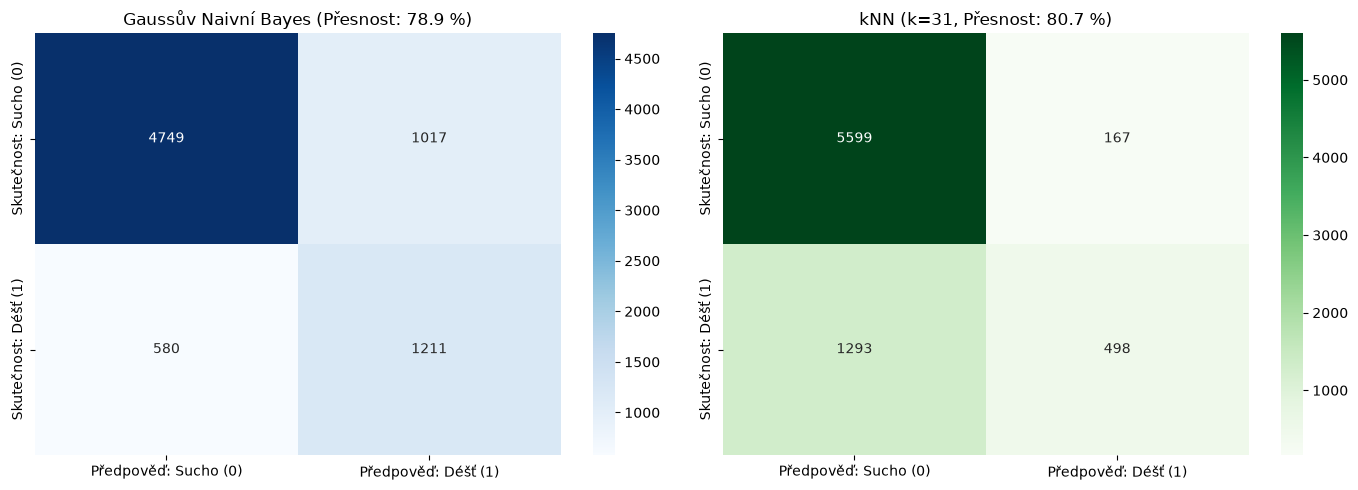

In [16]:
# tabulka
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# 1. Kontingenční tabulka pro Naive Bayes
cm_gnb = confusion_matrix(y, gnb_preds)
sns.heatmap(cm_gnb, annot=True, fmt='d', cmap='Blues', ax=ax[0],
            xticklabels=['Předpověď: Sucho (0)', 'Předpověď: Déšť (1)'],
            yticklabels=['Skutečnost: Sucho (0)', 'Skutečnost: Déšť (1)'])
ax[0].set_title(f"Gaussův Naivní Bayes (Přesnost: {gnb_scores.mean()*100:.1f} %)")

# 2. Kontingenční tabulka pro kNN
cm_knn = confusion_matrix(y, knn_pred)
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Greens', ax=ax[1],
            xticklabels=['Předpověď: Sucho (0)', 'Předpověď: Déšť (1)'],
            yticklabels=['Skutečnost: Sucho (0)', 'Skutečnost: Déšť (1)'])
ax[1].set_title(f"kNN (k={nejlepsi_k}, Přesnost: {knn_vysledky[nejlepsi_k]*100:.1f} %)")

plt.tight_layout()
plt.show()